# 07. Referral threshold, decision curve and threshold uncertainty

**Track 5 · Owner: Nero (Nyi Htut Oo) · Action items A2, A3, A4 · Criteria 1, 4, 6 · Professor F1, F5**

| Item | What this notebook delivers | Output |
|------|-----------------------------|--------|
| A2 | Threshold sweep in physician units: referrals / 1,000, strokes caught / 1,000, sensitivity, PPV, referrals per stroke caught, expected cost | `threshold_sweep.csv`, `threshold_operating_points.csv`, `threshold_simple_vs_final.csv`, `threshold_sweep.png` |
| A3 | Decision curve: net benefit of the model, age-only, refer-all and refer-none across the cost-ratio range | `decision_curve.csv`, `decision_curve_summary.csv`, `decision_curve_useful_range.csv`, `decision_curve.png` |
| A4 | Bootstrap CI for the cost-minimising threshold (whole pipeline, B = 200, m = 5), cost-curve flatness band, physician units at the CI ends, cost-ratio sensitivity | `threshold_ci.csv`, `threshold_bootstrap_pipeline.csv`, `threshold_physician_units.csv`, `threshold_selection_cv.csv`, `threshold_uncertainty.png`, `threshold_by_cost_ratio.png` |

**Inputs.** Track 3's out-of-fold predictions `data/interim/oof_final.csv` (column `p_mi` is the referral model, `p_age_only` the age-only comparator) and `oof_simple.csv` (complete-case model). Both are written by `06_model.ipynb`, which `run_all.py` runs first. For A4 the whole Track 3 pipeline is re-run inside the bootstrap, using the shared code in `src/modeling.py`.

**Decision rule (KB 02).** With cost ratio R = C_FN / C_FP, refer a patient when predicted risk ≥ p\* = 1 / (1 + R). The team fixed **R = 20** (p\* = 4.76%) before any threshold analysis ([docs/cost_ratio.md](../docs/cost_ratio.md)). Every result is repeated over R = 5, 10, 20, 50, 100.

**Units.** Costs are counted in units of one unnecessary referral (C_FP = 1), so a missed stroke costs R. Expected cost per 1,000 patients = 1000 · (FP + R · FN) / n. Net benefit per 1,000 = net strokes caught per 1,000 patients. At t = p\* the two are linked: cost = R · (1000 · prevalence − 1000 · NB), so **minimising expected cost at R is the same as maximising net benefit at p\***.

**Reproducibility.** All randomness is seeded from `SEED = 42` (`src/config.py`). Shared code: [`src/threshold.py`](../src/threshold.py). Net benefit uses `net_benefit()` and `p_star()` from `src/hypotheses.py`, so the numbers match Track 4's H1 and H2 exactly.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.config import (ALPHA, COST_RATIO, COST_RATIO_GRID, DATA_INTERIM, FIGURES, N_BOOT,
                        N_BOOT_PIPELINE, N_IMPUTATIONS, SEED, TABLES, TARGET)
from src.data import load_raw
from src.modeling import prepare
from src.threshold import (THRESHOLD_GRID, best_threshold, cross_fitted_selection, decision_curve,
                           expected_cost, flat_band, net_benefit, oof_only_bootstrap,
                           operating_point, p_star, pipeline_bootstrap, sweep_table, useful_range)

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
FLOAT_FMT = "%.10g"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

R = COST_RATIO                      # 20, decided in A1
PSTAR = p_star(R)                   # 1 / 21 = 4.76%
R_GRID = COST_RATIO_GRID            # 5, 10, 20, 50, 100
GRID = THRESHOLD_GRID               # 0.5% to 30%, step 0.05 percentage points
B_PIPE = N_BOOT_PIPELINE            # 200 whole-pipeline resamples
B_OOF = 2_000                       # cheap OOF-only resamples (comparison only)
print(f"R = {R}, p* = {PSTAR:.4f}; grid {GRID[0]:.3f} to {GRID[-1]:.3f} ({len(GRID)} thresholds)")
print(f"Whole-pipeline bootstrap: B = {B_PIPE}, m = {N_IMPUTATIONS}")

R = 20, p* = 0.0476; grid 0.005 to 0.300 (591 thresholds)
Whole-pipeline bootstrap: B = 200, m = 5


In [2]:
oof = pd.read_csv(DATA_INTERIM / "oof_final.csv")
y = oof[TARGET].to_numpy(int)
p = oof["p_mi"].to_numpy(float)
p_age = oof["p_age_only"].to_numpy(float)
n, events = len(y), int(y.sum())
prev = y.mean()
print(f"oof_final.csv: n = {n:,}, strokes = {events}, prevalence = {prev:.4f}")

# Consistency check with Track 4 (hyp_h2.csv, full data, R = 20)
h2 = pd.read_csv(TABLES / "hyp_h2.csv")
nb_track4 = h2.loc[(h2["data"] == "full data") & (h2["R"] == R), "nb_model"].item()
nb_here = net_benefit(y, p, PSTAR)
print(f"NB at p* (this notebook) = {nb_here:.6f}; Track 4 H2 = {nb_track4:.6f}")
assert np.isclose(nb_here, nb_track4), "predictions differ from the ones Track 4 used"

oof_final.csv: n = 5,109, strokes = 249, prevalence = 0.0487
NB at p* (this notebook) = 0.025592; Track 4 H2 = 0.025592


## A2. Threshold sweep in physician units

For every threshold from 0.5% to 30% we count how many patients would be referred and how many of the 249 strokes would be among them. Everything is out of fold: each patient's risk comes from a model that never saw that patient.

The table below gives the operating point at each cost ratio's threshold p\* = 1/(1+R), with Wilson 95% CIs. These CIs cover sampling variation in the counts at a **fixed** threshold; uncertainty in the threshold itself is A4.

In [3]:
sweep = sweep_table(y, p, R)
sweep.to_csv(TABLES / "threshold_sweep.csv", index=False, float_format=FLOAT_FMT)

ops = []
for r in R_GRID:
    row = operating_point(y, p, p_star(r))
    row = {"R": r, "p_star": p_star(r), **row,
           "net_benefit_per_1000": 1000 * net_benefit(y, p, p_star(r)),
           "expected_cost_per_1000": 1000 * (row["FP"] + r * row["FN"]) / n}
    ops.append(row)
ops = pd.DataFrame(ops)
ops.to_csv(TABLES / "threshold_operating_points.csv", index=False, float_format=FLOAT_FMT)

show = ops[["R", "p_star", "referrals_per_1000", "strokes_caught_per_1000", "sensitivity",
            "sensitivity_low", "sensitivity_high", "ppv", "ppv_low", "ppv_high",
            "referrals_per_stroke_caught", "net_benefit_per_1000", "expected_cost_per_1000"]]
display(show.round(3))

,R,p_star,referrals_per_1000,strokes_caught_per_1000,sensitivity,sensitivity_low,sensitivity_high,ppv,ppv_low,ppv_high,referrals_per_stroke_caught,net_benefit_per_1000,expected_cost_per_1000
0,5,0.167,78.685,15.463,0.317,0.263,0.377,0.197,0.161,0.238,5.089,2.819,229.595
1,10,0.091,184.185,31.709,0.651,0.590,0.707,0.172,0.149,0.198,5.809,16.461,322.764
2,20,0.048,302.016,38.755,0.795,0.741,0.841,0.128,0.113,0.146,7.793,25.592,462.909
3,50,0.020,488.941,45.410,0.932,0.893,0.957,0.093,0.082,0.105,10.767,36.539,609.904
4,100,0.010,615.776,47.759,0.980,0.954,0.991,0.078,0.069,0.087,12.893,42.079,665.884


In [4]:
# Start-of-day check: complete-case predictions (oof_simple) vs the final MI
# predictions, on the 4,908 patients who have both (BMI recorded).
simple = pd.read_csv(DATA_INTERIM / "oof_simple.csv")
both = simple.merge(oof[["row_id", "p_mi"]], on="row_id")
cmp_rows = []
for label, col in (("Complete case (oof_simple)", "p"), ("MI (oof_final)", "p_mi")):
    op = operating_point(both[TARGET], both[col], PSTAR)
    cmp_rows.append({"predictions": label, "n": op["n"], "strokes": op["TP"] + op["FN"],
                     "referrals_per_1000": op["referrals_per_1000"],
                     "strokes_caught_per_1000": op["strokes_caught_per_1000"],
                     "sensitivity": op["sensitivity"], "ppv": op["ppv"],
                     "net_benefit_per_1000": 1000 * net_benefit(both[TARGET], both[col], PSTAR),
                     "t_hat": best_threshold(expected_cost(both[TARGET], both[col], R), GRID)})
cmp_simple = pd.DataFrame(cmp_rows)
cmp_simple.to_csv(TABLES / "threshold_simple_vs_final.csv", index=False, float_format=FLOAT_FMT)
display(cmp_simple.round(4))

,predictions,n,strokes,referrals_per_1000,strokes_caught_per_1000,sensitivity,ppv,net_benefit_per_1000,t_hat
0,Complete case (oof_simple),4908,209,264.6699,31.9886,0.7512,0.1209,20.3545,0.0375
1,MI (oof_final),4908,209,292.5835,33.2111,0.7799,0.1135,20.2425,0.0355


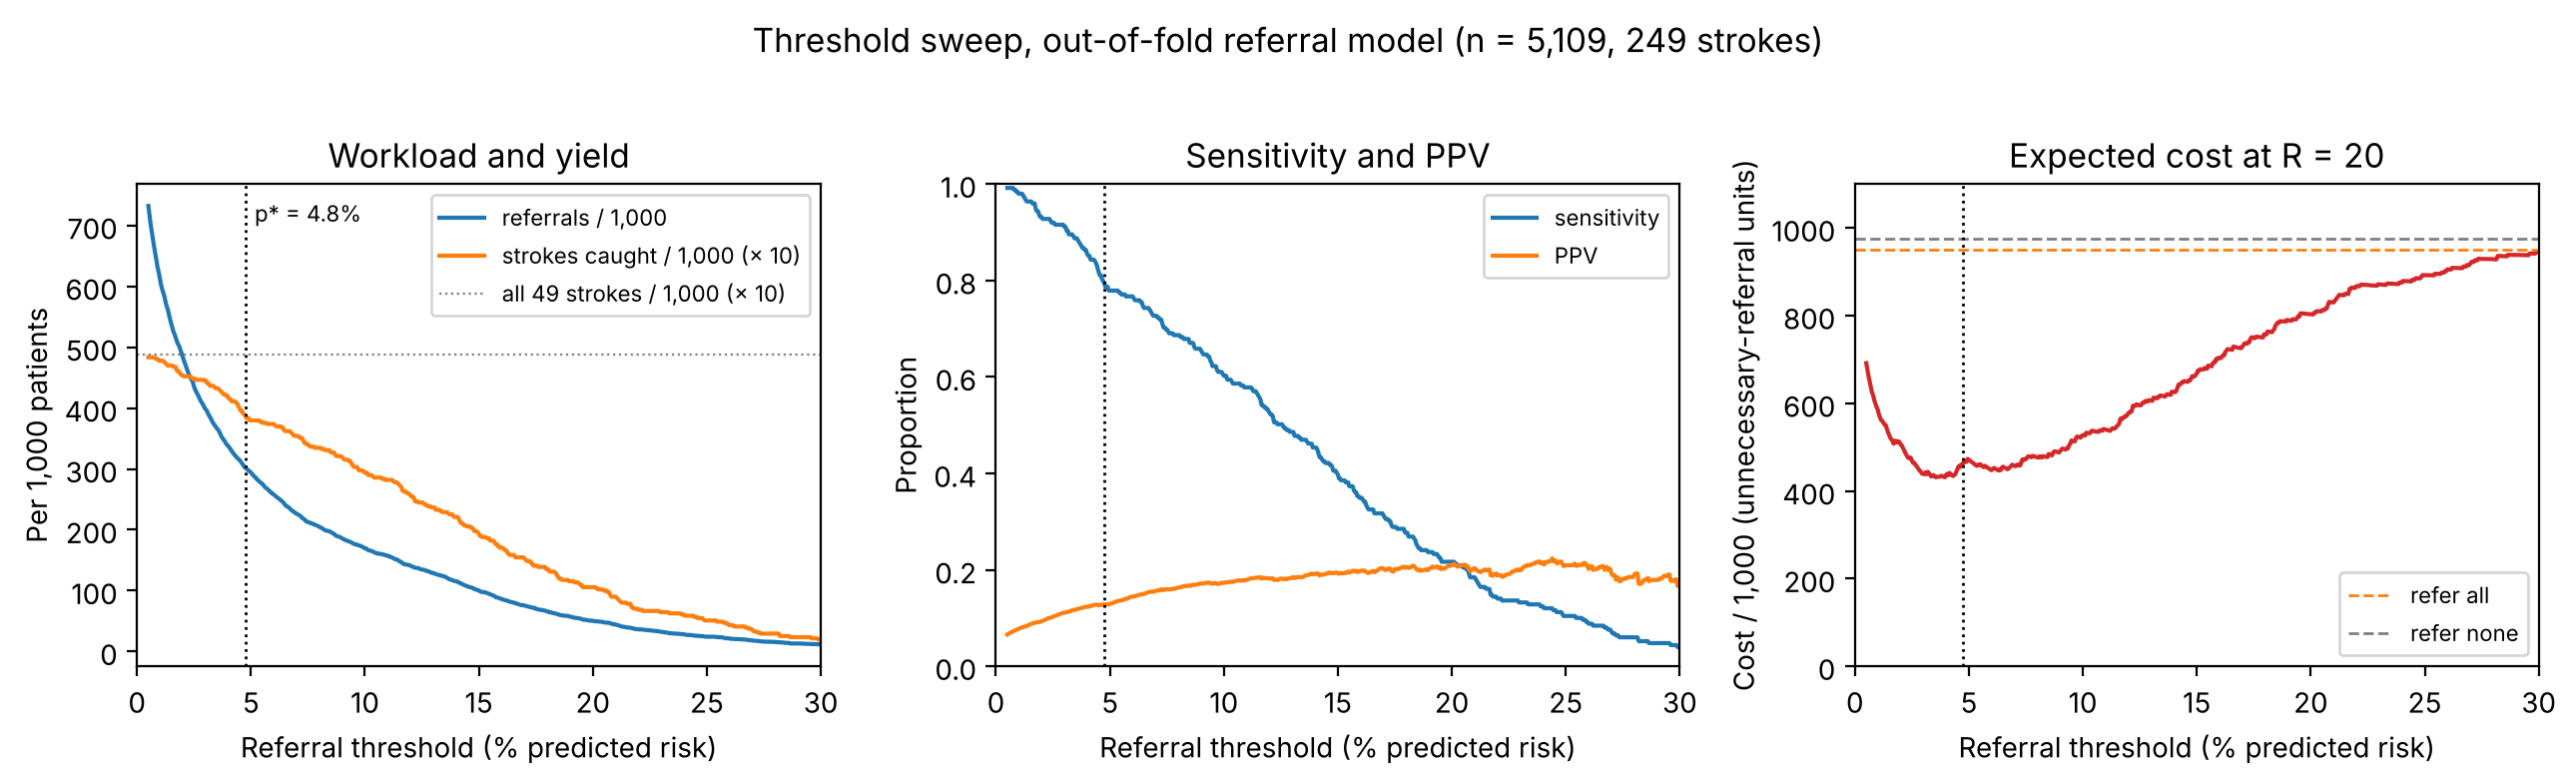

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
pct = 100 * sweep["threshold"]

ax = axes[0]
ax.plot(pct, sweep["referrals_per_1000"], label="referrals / 1,000")
ax.plot(pct, sweep["strokes_caught_per_1000"] * 10, label="strokes caught / 1,000 (× 10)")
ax.axhline(1000 * prev * 10, color="grey", lw=0.8, ls=":", label=f"all {1000 * prev:.0f} strokes / 1,000 (× 10)")
ax.set_xlabel("Referral threshold (% predicted risk)")
ax.set_ylabel("Per 1,000 patients")
ax.set_title("Workload and yield")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(pct, sweep["sensitivity"], label="sensitivity")
ax.plot(pct, sweep["ppv"], label="PPV")
ax.set_xlabel("Referral threshold (% predicted risk)")
ax.set_ylabel("Proportion")
ax.set_ylim(0, 1)
ax.set_title("Sensitivity and PPV")
ax.legend(fontsize=8)

ax = axes[2]
ax.plot(pct, sweep[f"expected_cost_per_1000_R{R:g}"], color="C3")
ax.axhline(1000 * (1 - prev), color="C1", ls="--", lw=1, label="refer all")
ax.axhline(1000 * R * prev, color="grey", ls="--", lw=1, label="refer none")
ax.set_xlabel("Referral threshold (% predicted risk)")
ax.set_ylabel("Cost / 1,000 (unnecessary-referral units)")
ax.set_title(f"Expected cost at R = {R}")
ax.set_ylim(0, 1100)
ax.legend(fontsize=8, loc="lower right")

for ax in axes:
    ax.axvline(100 * PSTAR, color="k", ls=":", lw=1)
    ax.set_xlim(0, 30)
axes[0].text(100 * PSTAR + 0.4, axes[0].get_ylim()[1] * 0.92, f"p* = {100 * PSTAR:.1f}%", fontsize=8)
fig.suptitle(f"Threshold sweep, out-of-fold referral model (n = {n:,}, {events} strokes)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "threshold_sweep.png", dpi=200, bbox_inches="tight")
plt.show()

**What A2 shows.** At our cost ratio R = 20 the rule refers everyone with predicted risk of 4.8% or more. That means about **302 referrals per 1,000 patients** (95% CI 290 to 315). Among them are about **39 of the 49 strokes per 1,000**, so sensitivity is 79.5% (74.1% to 84.1%) and 198 of the 249 strokes are caught. PPV is 12.8% (11.3% to 14.6%), which means the physician makes about **7.8 referrals for each stroke caught**. For comparison, referring everyone would mean 1,000 referrals to catch all 49.

Moving the threshold is a trade between workload and missed strokes. At R = 10 (p\* = 9.1%) the clinic refers only 184 per 1,000 but catches 32 strokes per 1,000. At R = 50 (p\* = 2.0%) it refers 489 per 1,000 and catches 45.

The complete-case predictions from the morning of Day 1 (`oof_simple.csv`) give almost the same answer as the final MI predictions on the 4,908 patients who have both: net benefit 20.4 vs 20.2 net strokes per 1,000 at p\*. So swapping in the final predictions did not change any conclusion.

The expected-cost curve (right panel) falls steeply below 2%, has its lowest point a little **below** p\*, and then rises slowly. A4 checks whether that gap between the lowest point and p\* is real or just noise.

## A3. Decision curve: what happens when the cost ratio moves (professor point F1)

Net benefit (Vickers & Elkin 2006) at threshold t is TP/n − FP/n · t/(1 − t), shown here as **net strokes caught per 1,000 patients**. The threshold and the cost ratio are two names for the same thing: t = 1/(1 + R), so the top axis shows R. A strategy is worth using only where its curve is above the others.

Comparators: refer everyone, refer no one (NB = 0) and the **age-only** model, which asks whether the extra predictors help beyond age. The formal tests of these comparisons are Track 4's H1 (full vs age-only) and H2 (model vs best default), with bootstrap CIs; this section shows the whole curve.

In [6]:
dc = decision_curve(y, {"Referral model": p, "Age only": p_age}, GRID)
dc.to_csv(TABLES / "decision_curve.csv", index=False, float_format=FLOAT_FMT)

summ = []
for r in R_GRID:
    t = p_star(r)
    nb = {"Referral model": net_benefit(y, p, t), "Age only": net_benefit(y, p_age, t),
          "Refer all": net_benefit(y, np.ones_like(p), t), "Refer none": 0.0}
    best = max(nb, key=nb.get)
    summ.append({"R": r, "p_star": t, **{f"nb_per_1000_{k}": 1000 * v for k, v in nb.items()},
                 "best_strategy": best,
                 "model_minus_best_default_per_1000": 1000 * (nb["Referral model"] - max(nb["Refer all"], 0.0)),
                 "model_minus_age_only_per_1000": 1000 * (nb["Referral model"] - nb["Age only"])})
dc_summary = pd.DataFrame(summ)
dc_summary.to_csv(TABLES / "decision_curve_summary.csv", index=False, float_format=FLOAT_FMT)
display(dc_summary.round(2))

ranges = []
for label, comp in (("beats refer-all and refer-none", ["Refer all", "Refer none"]),
                    ("also beats age-only", ["Refer all", "Refer none", "Age only"])):
    rng_ = useful_range(dc, "Referral model", comp)
    lo, hi = rng_ if rng_ else (np.nan, np.nan)
    ranges.append({"comparison": f"Referral model {label}", "threshold_low": lo, "threshold_high": hi,
                   "R_low": (1 - hi) / hi, "R_high": (1 - lo) / lo})
age_rng = useful_range(dc, "Age only", ["Refer all", "Refer none"])
ranges.append({"comparison": "Age only beats refer-all and refer-none", "threshold_low": age_rng[0],
               "threshold_high": age_rng[1], "R_low": (1 - age_rng[1]) / age_rng[1],
               "R_high": (1 - age_rng[0]) / age_rng[0]})
useful = pd.DataFrame(ranges)
useful.to_csv(TABLES / "decision_curve_useful_range.csv", index=False, float_format=FLOAT_FMT)
display(useful.round(4))

# Share of the grid where the model and age-only differ by less than 1 net stroke / 1,000
gap = (dc["Referral model"] - dc["Age only"]).abs()
print(f"|NB(model) − NB(age only)| < 1 per 1,000 at {np.mean(gap < 1):.0%} of thresholds; "
      f"largest gap {gap.max():.1f} per 1,000 at t = {dc.loc[gap.idxmax(), 'threshold']:.3f}")

,R,p_star,nb_per_1000_Referral model,nb_per_1000_Age only,nb_per_1000_Refer all,nb_per_1000_Refer none,best_strategy,model_minus_best_default_per_1000,model_minus_age_only_per_1000
0,5,0.17,2.82,4.15,-141.51,0.0,Age only,2.82,-1.33
1,10,0.09,16.46,14.99,-46.39,0.0,Referral model,16.46,1.47
2,20,0.05,25.59,26.29,1.17,0.0,Age only,24.42,-0.69
3,50,0.02,36.54,37.38,29.71,0.0,Age only,6.83,-0.84
4,100,0.01,42.08,42.30,39.22,0.0,Age only,2.85,-0.23


,comparison,threshold_low,threshold_high,R_low,R_high
0,Referral model beats refer-all and refer-none,0.005,0.207,3.8309,199.0000
1,Referral model also beats age-only,0.051,0.101,8.9010,18.6078
2,Age only beats refer-all and refer-none,0.005,0.205,3.8780,199.0000


|NB(model) − NB(age only)| < 1 per 1,000 at 61% of thresholds; largest gap 3.3 per 1,000 at t = 0.064


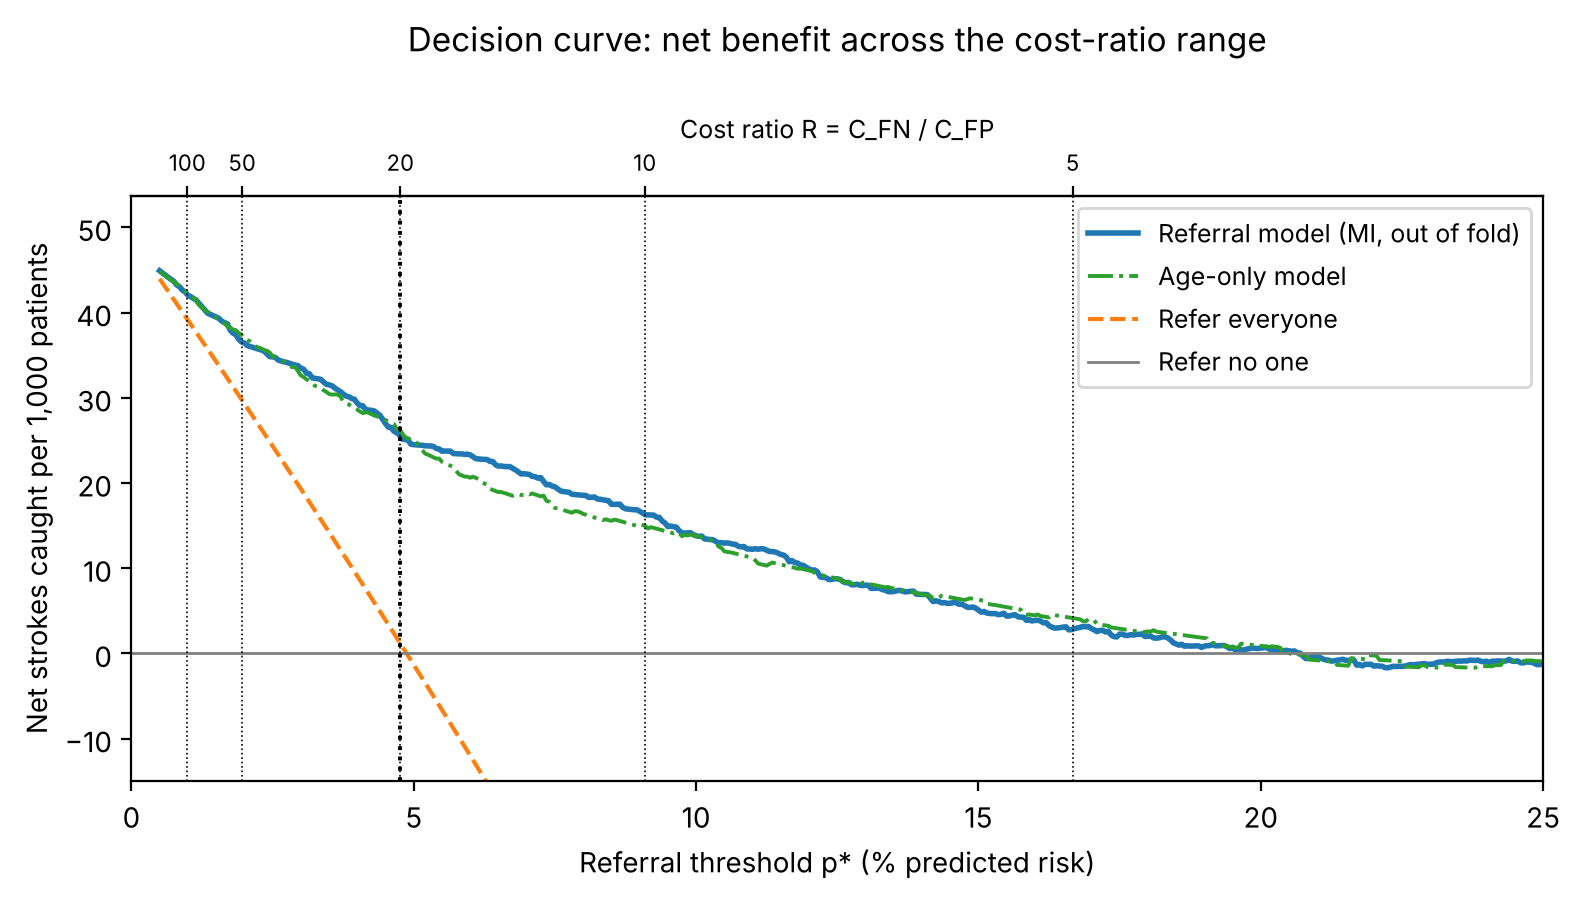

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.6))
pct = 100 * dc["threshold"]
ax.plot(pct, dc["Referral model"], lw=2, label="Referral model (MI, out of fold)")
ax.plot(pct, dc["Age only"], lw=1.4, ls="-.", color="C2", label="Age-only model")
ax.plot(pct, dc["Refer all"], ls="--", color="C1", label="Refer everyone")
ax.axhline(0, color="grey", lw=1, label="Refer no one")
for r in R_GRID:
    ax.axvline(100 * p_star(r), color="k", ls=":", lw=0.6)
ax.axvline(100 * PSTAR, color="k", ls=":", lw=1.4)
ax.set_xlim(0, 25)
ax.set_ylim(-15, 1000 * prev + 5)
ax.set_xlabel("Referral threshold p* (% predicted risk)")
ax.set_ylabel("Net strokes caught per 1,000 patients")
ax.set_title("Decision curve: net benefit across the cost-ratio range\n", pad=8)
ax.legend(loc="upper right", fontsize=9)

top = ax.secondary_xaxis("top")
top.set_ticks([100 * p_star(r) for r in R_GRID], labels=[f"{r}" for r in R_GRID])
top.tick_params(labelsize=8)
top.set_xlabel("Cost ratio R = C_FN / C_FP", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "decision_curve.png", dpi=200, bbox_inches="tight")
plt.show()

**What A3 shows (answer to F1).** The referral model has higher net benefit than both "refer everyone" and "refer no one" for every threshold from 0.5% to 20.7%. In cost-ratio terms, that is every R from about 4 to 199, so the model is useful over the whole range we consider (R = 5 to 100). At R = 20 the model gives 25.6 net strokes caught per 1,000, against 1.2 for refer-all, a gain of 24.4 per 1,000 (Track 4's H2 gives the CI: 21.9 to 26.9). The gain is small at the two ends. At R = 5 only a few patients are above 16.7% (gain 2.8 per 1,000, and Track 4's CI includes 0). At R = 100 referring everyone is almost as good as the model (42.1 vs 39.2 per 1,000).

**The model and the age-only model are almost the same curve.** They differ by less than 1 net stroke per 1,000 at 61% of thresholds, and the largest gap is 3.3 per 1,000 (at 6.4%). The full model is above age-only only for thresholds between 5.1% and 10.1% (R about 9 to 19). At our own R = 20, age-only is actually 0.7 per 1,000 higher. This agrees with Track 4's H1: the extra predictors improve the likelihood, but the gain in net benefit has a CI that includes 0. For the referral decision, almost all of the value comes from age.

So when the cost ratio moves, the threshold moves a lot (from 16.7% at R = 5 to 1.0% at R = 100), but the main message does not change: using the model is better than either default across the range, and it is no better than age alone.

## A4. How sure are we about the threshold? (professor point F5)

A recommended threshold is an estimate. KB 06 separates two sources of uncertainty, and we report them separately:

1. **Sampling:** a different sample of patients would give a different model and a different cost-minimising threshold. → bootstrap CI (A4.2).
2. **The cost ratio:** R = 20 is a judgement, not data. → repeat everything over R = 5…100 (A4.5 and the decision curve above).

Two different thresholds appear below, so we name them:

- **p\* = 1/(1 + R)** is the *decision rule*. It is fixed by R alone and is correct if predicted risks are calibrated.
- **t̂** is the *empirical* threshold that minimises expected cost on our out-of-fold predictions. If the model were perfectly calibrated, t̂ would sit near p\*. The bootstrap CI is a CI for t̂.

### A4.1 Point estimate and flatness of the cost curve

In [8]:
cost = expected_cost(y, p, R, GRID)
t_hat = best_threshold(cost, GRID)
i_pstar = int(np.argmin(np.abs(GRID - PSTAR)))
band5 = flat_band(cost, 0.05, GRID)
band10 = flat_band(cost, 0.10, GRID)
print(f"t̂ (cost-minimising threshold, R = {R}) = {t_hat:.4f}; minimum cost = {cost.min():.1f} per 1,000")
print(f"cost at p* = {PSTAR:.4f}: {cost[i_pstar]:.1f} per 1,000 "
      f"({100 * (cost[i_pstar] / cost.min() - 1):.1f}% above the minimum)")
print(f"thresholds within 5% of the minimum cost:  {band5[0]:.4f} to {band5[1]:.4f}")
print(f"thresholds within 10% of the minimum cost: {band10[0]:.4f} to {band10[1]:.4f}")
print(f"For scale: 5% of the minimum = {0.05 * cost.min():.1f} referral-units per 1,000 "
      f"= {0.05 * cost.min() / R:.2f} missed strokes per 1,000")

t̂ (cost-minimising threshold, R = 20) = 0.0355; minimum cost = 431.2 per 1,000
cost at p* = 0.0476: 462.9 per 1,000 (7.4% above the minimum)
thresholds within 5% of the minimum cost:  0.0275 to 0.0450
thresholds within 10% of the minimum cost: 0.0250 to 0.0750
For scale: 5% of the minimum = 21.6 referral-units per 1,000 = 1.08 missed strokes per 1,000


### A4.2 Whole-pipeline bootstrap CI for t̂

For each of B = 200 resamples (`N_BOOT_PIPELINE`), we:

1. draw a **stratified** bootstrap sample (strokes and non-strokes resampled separately, so every resample keeps 249 strokes);
2. re-run Track 3's **whole pipeline** on it: stratified 5-fold CV, BMI imputed m = 5 times on the training fold only, logistic model fitted, test-fold predictions averaged over the 5 imputations;
3. find the threshold that minimises expected cost on that resample's out-of-fold predictions, for each R.

The CI is the 2.5th and 97.5th percentiles of those 200 thresholds. B = 200 and m = 5 (rather than 10,000 and 20) keep the run to a few minutes; **this is stated in the report**. With B = 200 the percentile ends rest on about 5 resamples each, so the CI ends are themselves rough to about ±0.5 percentage points.

**One change from Track 3's `oof_predictions()`:** a bootstrap sample repeats patients, so the folds are built with `StratifiedGroupKFold` grouped on the original patient. Otherwise copies of one patient could sit in both the training and the test fold, and the out-of-fold predictions would look better than they are.

In [9]:
df = prepare(load_raw())
assert len(df) == n and int(df[TARGET].sum()) == events

t0 = time.time()
boot_pipe, boot_costs = pipeline_bootstrap(df, R_GRID, B=B_PIPE, seed=SEED, m=N_IMPUTATIONS)
print(f"Whole-pipeline bootstrap: {B_PIPE} resamples in {time.time() - t0:.0f} s")
boot_pipe.to_csv(TABLES / "threshold_bootstrap_pipeline.csv", index=False, float_format=FLOAT_FMT)
display(boot_pipe[[f"t_star_R{r:g}" for r in R_GRID]].describe().round(4))

  resample 25/200


  resample 50/200


  resample 75/200


  resample 100/200


  resample 125/200


  resample 150/200


  resample 175/200


  resample 200/200


Whole-pipeline bootstrap: 200 resamples in 179 s


,t_star_R5,t_star_R10,t_star_R20,t_star_R50,t_star_R100
count,200.0000,200.0000,200.0000,200.0000,200.0000
mean,0.1563,0.0812,0.0450,0.0207,0.0119
std,0.0328,0.0164,0.0103,0.0065,0.0035
min,0.0855,0.0500,0.0255,0.0065,0.0050
25%,0.1339,0.0695,0.0369,0.0159,0.0095
50%,0.1535,0.0780,0.0435,0.0202,0.0115
75%,0.1715,0.0905,0.0525,0.0255,0.0135
max,0.2945,0.1350,0.0750,0.0395,0.0290


### A4.3 Cheaper OOF-only bootstrap (for comparison)

Resample patients but keep their out-of-fold predictions fixed. This ignores the uncertainty from refitting the model and re-imputing BMI, so KB 06 expects it to be **too narrow**. We show it only as a check on that expectation; the CI we report is the whole-pipeline one.

In [10]:
boot_oof = oof_only_bootstrap(y, p, R_GRID, B=B_OOF, seed=SEED)

def pct_ci(x):
    lo, hi = np.quantile(x, [ALPHA / 2, 1 - ALPHA / 2])
    return float(lo), float(hi)

rows = []
for r in R_GRID:
    c_r = expected_cost(y, p, r, GRID)
    th_r = best_threshold(c_r, GRID)
    col = f"t_star_R{r:g}"
    lo_p, hi_p = pct_ci(boot_pipe[col])
    lo_o, hi_o = pct_ci(boot_oof[col])
    b5, b10 = flat_band(c_r, 0.05, GRID), flat_band(c_r, 0.10, GRID)
    # In how many resamples is the fixed rule p* within 5% / 10% of that resample's minimum cost?
    ratio = boot_pipe[f"cost_at_pstar_R{r:g}"] / boot_pipe[f"min_cost_R{r:g}"]
    rows.append({
        "R": r, "p_star": p_star(r), "t_hat": th_r,
        "ci_low_pipeline": lo_p, "ci_high_pipeline": hi_p, "boot_median_pipeline": float(boot_pipe[col].median()),
        "ci_low_oof_only": lo_o, "ci_high_oof_only": hi_o,
        "flat5_low": b5[0], "flat5_high": b5[1], "flat10_low": b10[0], "flat10_high": b10[1],
        "p_star_inside_pipeline_ci": lo_p <= p_star(r) <= hi_p,
        "share_resamples_pstar_within_5pct": float(np.mean(ratio <= 1.05)),
        "share_resamples_pstar_within_10pct": float(np.mean(ratio <= 1.10)),
        "min_cost_per_1000": float(c_r.min()),
        "cost_at_pstar_per_1000": float(c_r[np.argmin(np.abs(GRID - p_star(r)))]),
        "B_pipeline": B_PIPE, "m": N_IMPUTATIONS, "B_oof_only": B_OOF,
    })
ci_table = pd.DataFrame(rows)
ci_table.to_csv(TABLES / "threshold_ci.csv", index=False, float_format=FLOAT_FMT)
display(ci_table.drop(columns=["B_pipeline", "m", "B_oof_only"]).round(4).T)

w_pipe = ci_table["ci_high_pipeline"] - ci_table["ci_low_pipeline"]
w_oof = ci_table["ci_high_oof_only"] - ci_table["ci_low_oof_only"]
print("CI width, whole pipeline vs OOF-only (percentage points):")
print(pd.DataFrame({"R": ci_table["R"], "pipeline": 100 * w_pipe, "oof_only": 100 * w_oof}).round(2).to_string(index=False))

,0,1,2,3,4
R,5,10,20,50,100
p_star,0.1667,0.0909,0.0476,0.0196,0.0099
t_hat,0.1385,0.0845,0.0355,0.0295,0.0115
ci_low_pipeline,0.11,0.0569,0.0285,0.0105,0.0065
ci_high_pipeline,0.2346,0.1191,0.065,0.034,0.0195
boot_median_pipeline,0.1535,0.078,0.0435,0.0202,0.0115
ci_low_oof_only,0.112,0.064,0.0295,0.0115,0.0075
ci_high_oof_only,0.206,0.1135,0.0705,0.0355,0.0175
flat5_low,0.1,0.0595,0.0275,0.025,0.007
flat5_high,0.2165,0.1155,0.045,0.0315,0.0125


CI width, whole pipeline vs OOF-only (percentage points):
  R  pipeline  oof_only
  5     12.46      9.40
 10      6.21      4.95
 20      3.65      4.10
 50      2.35      2.40
100      1.30      1.00


### A4.4 Choosing the threshold on the data vs using p\* (an honest comparison)

t̂ is chosen and then evaluated on the same patients, so its cost looks better than it is (KB 02, common mistakes). To compare it fairly with the fixed rule p\*, we **cross-fit**: for each of Track 3's 5 folds, choose t̂ on the other 4 folds and apply it to the held-out fold.

In [11]:
sel = cross_fitted_selection(oof, "p_mi", R, GRID)
sel.to_csv(TABLES / "threshold_selection_cv.csv", index=False, float_format=FLOAT_FMT)
display(sel.round(4))
tot = sel.groupby("rule")[["n", "FP", "FN", "cost"]].sum()
tot["cost_per_1000"] = 1000 * tot["cost"] / tot["n"]
display(tot.round(1))
d = tot.loc["chosen on other folds", "cost_per_1000"] - tot.loc["fixed p* = 1/(1+R)", "cost_per_1000"]
print(f"Data-chosen threshold minus fixed p*: {d:+.1f} cost units per 1,000 "
      f"= {d / R:+.2f} missed-stroke equivalents per 1,000")

,fold,rule,threshold,n,FP,FN,cost
0,0,chosen on other folds,0.0355,1022,303,9,483
1,0,fixed p* = 1/(1+R),0.0476,1022,244,11,464
2,1,chosen on other folds,0.0430,1022,291,9,471
3,1,fixed p* = 1/(1+R),0.0476,1022,277,9,457
4,2,chosen on other folds,0.0395,1022,321,5,421
5,2,fixed p* = 1/(1+R),0.0476,1022,273,7,413
6,3,chosen on other folds,0.0355,1022,346,5,446
7,3,fixed p* = 1/(1+R),0.0476,1022,285,9,465
8,4,chosen on other folds,0.0430,1021,282,11,502
9,4,fixed p* = 1/(1+R),0.0476,1021,266,15,566


,n,FP,FN,cost,cost_per_1000
rule,,,,,
chosen on other folds,5109,1543,39,2323,454.7
fixed p* = 1/(1+R),5109,1345,51,2365,462.9


Data-chosen threshold minus fixed p*: -8.2 cost units per 1,000 = -0.41 missed-stroke equivalents per 1,000


### A4.5 Physician units at the recommended threshold and at the CI ends

In [12]:
r20 = ci_table.set_index("R").loc[R]
points = [
    ("Recommended rule p* = 1/(1+R)", PSTAR),
    ("Cost-minimising t̂ (point estimate)", r20["t_hat"]),
    ("t̂ 95% CI, lower end", r20["ci_low_pipeline"]),
    ("t̂ 95% CI, upper end", r20["ci_high_pipeline"]),
    ("5% flatness band, lower end", r20["flat5_low"]),
    ("5% flatness band, upper end", r20["flat5_high"]),
]
units = []
for label, t in points:
    op = operating_point(y, p, t)
    units.append({"point": label, "threshold": t,
                  "referrals_per_1000": op["referrals_per_1000"],
                  "strokes_caught_per_1000": op["strokes_caught_per_1000"],
                  "strokes_caught_of_249": op["TP"],
                  "sensitivity": op["sensitivity"], "ppv": op["ppv"],
                  "referrals_per_stroke_caught": op["referrals_per_stroke_caught"],
                  "net_benefit_per_1000": 1000 * (op["TP"] / n - op["FP"] / n * PSTAR / (1 - PSTAR)),
                  "expected_cost_per_1000": 1000 * (op["FP"] + R * op["FN"]) / n})
units = pd.DataFrame(units)
units.to_csv(TABLES / "threshold_physician_units.csv", index=False, float_format=FLOAT_FMT)
display(units.round(3))

,point,threshold,referrals_per_1000,strokes_caught_per_1000,strokes_caught_of_249,sensitivity,ppv,referrals_per_stroke_caught,net_benefit_per_1000,expected_cost_per_1000
0,Recommended rule p* = 1/(1+R),0.048,302.016,38.755,198,0.795,0.128,7.793,25.592,462.909
1,Cost-minimising t̂ (point estimate),0.036,364.846,43.257,221,0.888,0.119,8.434,27.178,431.200
2,"t̂ 95% CI, lower end",0.028,408.495,44.627,228,0.916,0.109,9.154,26.434,446.076
3,"t̂ 95% CI, upper end",0.065,240.947,36.211,185,0.743,0.150,6.654,25.974,455.275
4,"5% flatness band, lower end",0.028,415.150,44.627,228,0.916,0.107,9.303,26.101,452.730
5,"5% flatness band, upper end",0.045,314.739,39.930,204,0.819,0.127,7.882,26.189,450.969


Note: `net_benefit_per_1000` in this table is always weighted at R = 20 (weight p\*/(1 − p\*) = 1/20), so the rows can be compared with each other.

### A4.6 Figures

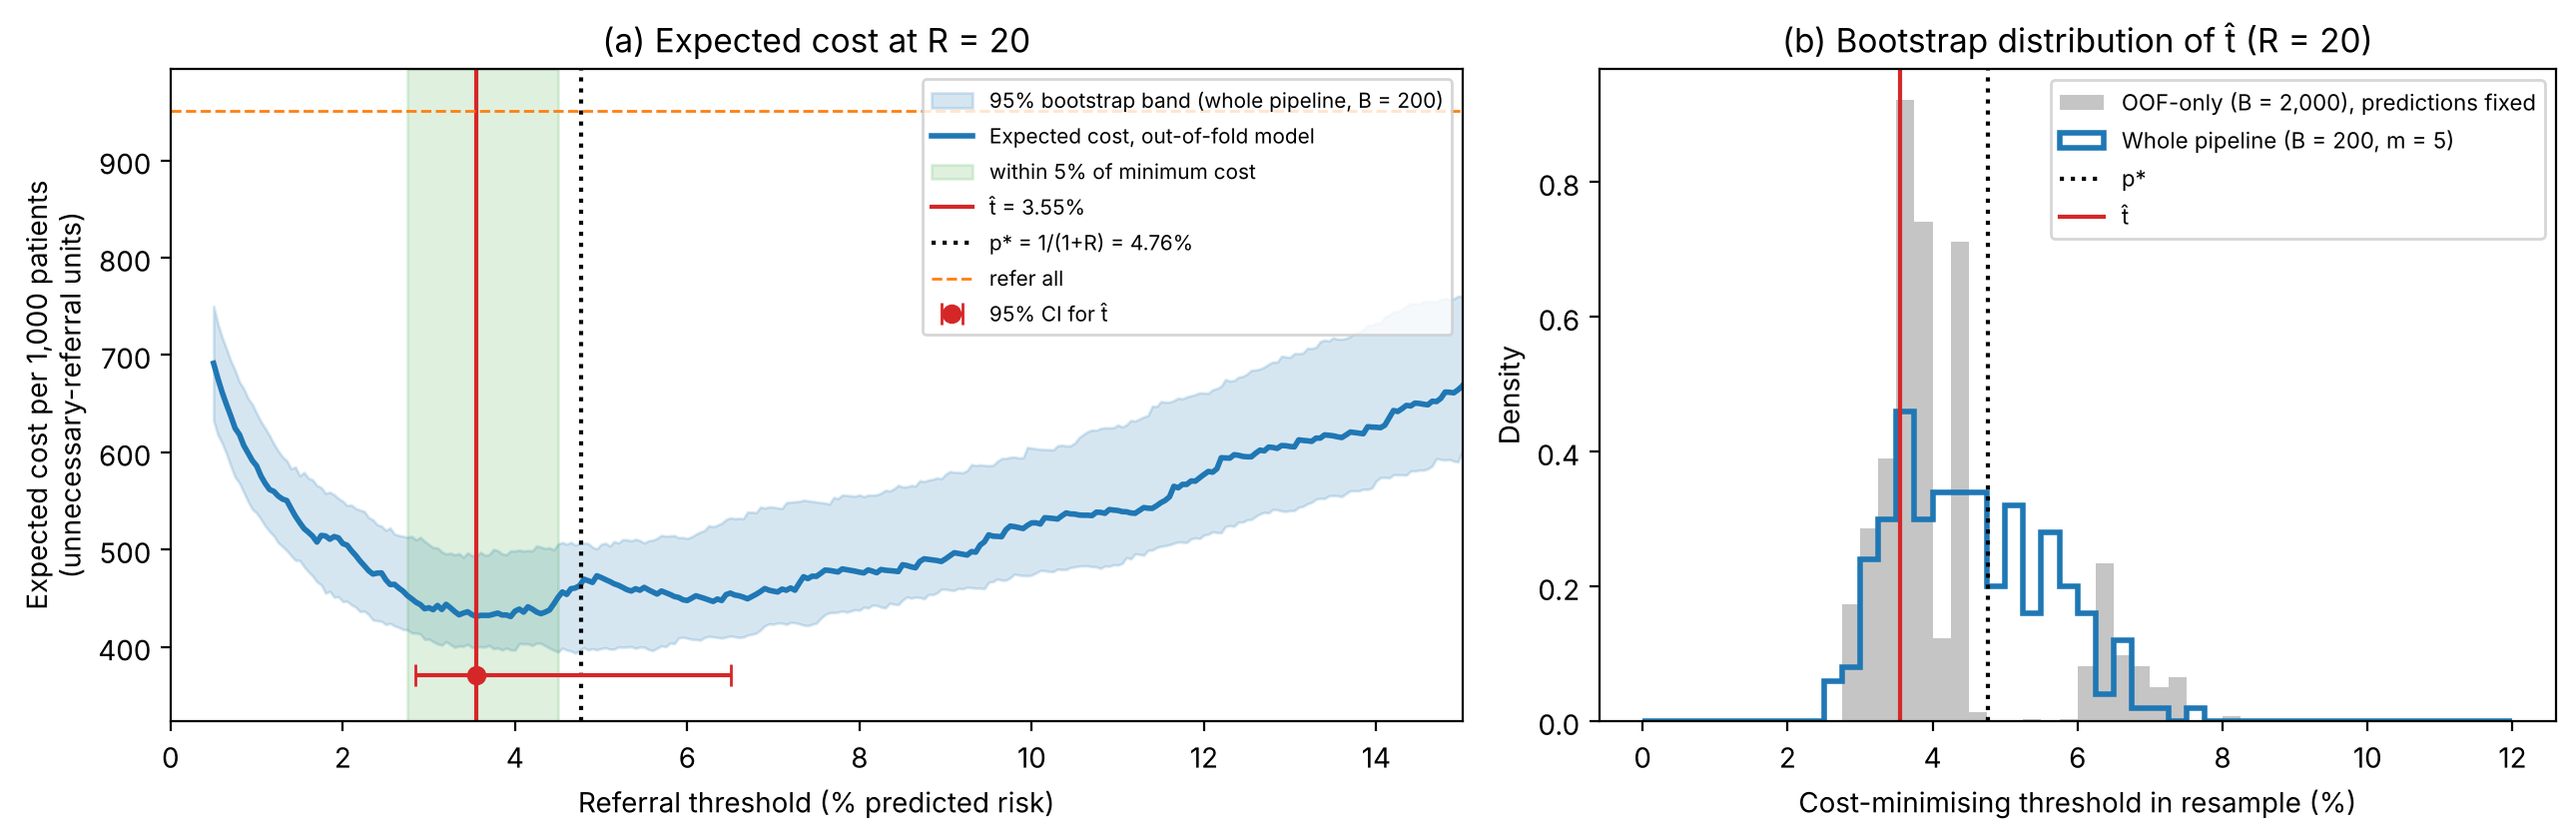

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.35, 1]})
pct = 100 * GRID

# (a) cost curve with whole-pipeline bootstrap band and flatness band
ax = axes[0]
C = boot_costs[R]
lo_band, hi_band = np.quantile(C, [ALPHA / 2, 1 - ALPHA / 2], axis=0)
ax.fill_between(pct, lo_band, hi_band, color="C0", alpha=0.18,
                label=f"95% bootstrap band (whole pipeline, B = {B_PIPE})")
ax.plot(pct, cost, color="C0", lw=2, label="Expected cost, out-of-fold model")
ax.axvspan(100 * band5[0], 100 * band5[1], color="C2", alpha=0.15, label="within 5% of minimum cost")
ax.axvline(100 * t_hat, color="C3", lw=1.5, label=f"t̂ = {100 * t_hat:.2f}%")
ax.axvline(100 * PSTAR, color="k", ls=":", lw=1.5, label=f"p* = 1/(1+R) = {100 * PSTAR:.2f}%")
ax.errorbar(100 * t_hat, cost.min() * 0.86,
            xerr=[[100 * (t_hat - r20["ci_low_pipeline"])], [100 * (r20["ci_high_pipeline"] - t_hat)]],
            fmt="o", color="C3", capsize=4, label="95% CI for t̂")
ax.axhline(1000 * (1 - prev), color="C1", ls="--", lw=1, label="refer all")
ax.set_xlim(0, 15)
ax.set_ylim(cost.min() * 0.75, 1000 * R * prev * 1.02)
ax.set_xlabel("Referral threshold (% predicted risk)")
ax.set_ylabel("Expected cost per 1,000 patients\n(unnecessary-referral units)")
ax.set_title(f"(a) Expected cost at R = {R}")
ax.legend(fontsize=7.5, loc="upper right")

# (b) bootstrap distribution of t̂: whole pipeline vs OOF-only
ax = axes[1]
bins = np.arange(0, 0.12 + 1e-9, 0.0025) * 100
ax.hist(100 * boot_oof[f"t_star_R{R:g}"], bins=bins, density=True, alpha=0.45, color="grey",
        label=f"OOF-only (B = {B_OOF:,}), predictions fixed")
ax.hist(100 * boot_pipe[f"t_star_R{R:g}"], bins=bins, density=True, histtype="step", lw=2, color="C0",
        label=f"Whole pipeline (B = {B_PIPE}, m = {N_IMPUTATIONS})")
ax.axvline(100 * PSTAR, color="k", ls=":", lw=1.5, label="p*")
ax.axvline(100 * t_hat, color="C3", lw=1.5, label="t̂")
ax.set_xlabel("Cost-minimising threshold in resample (%)")
ax.set_ylabel("Density")
ax.set_title(f"(b) Bootstrap distribution of t̂ (R = {R})")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "threshold_uncertainty.png", dpi=200, bbox_inches="tight")
plt.show()

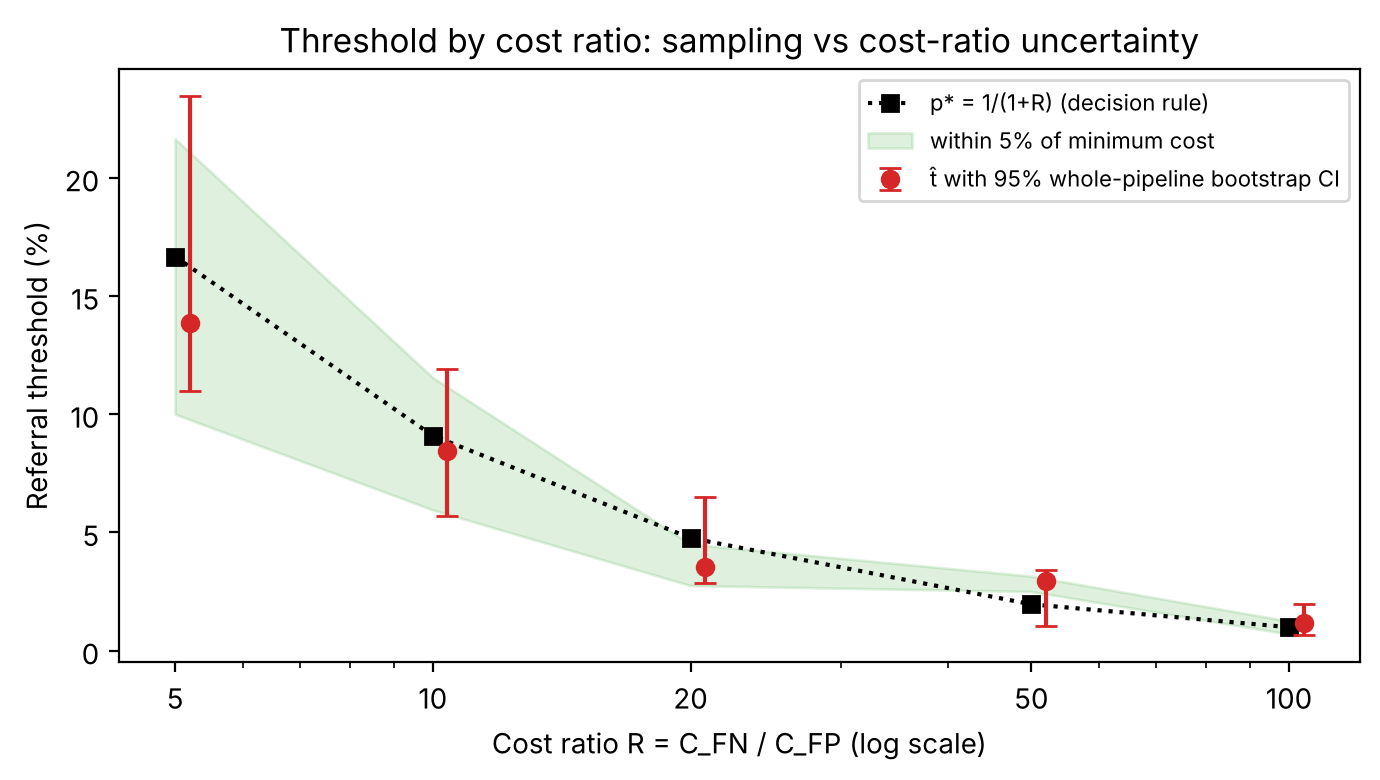

In [14]:
# Cost-ratio uncertainty, shown separately from sampling uncertainty (KB 06)
fig, ax = plt.subplots(figsize=(7, 4))
Rs = np.array(R_GRID, float)
ax.plot(Rs, 100 / (1 + Rs), "k:", marker="s", label="p* = 1/(1+R) (decision rule)")
yerr = 100 * np.vstack([ci_table["t_hat"] - ci_table["ci_low_pipeline"],
                        ci_table["ci_high_pipeline"] - ci_table["t_hat"]])
ax.errorbar(Rs * 1.04, 100 * ci_table["t_hat"], yerr=yerr, fmt="o", color="C3", capsize=4,
            label="t̂ with 95% whole-pipeline bootstrap CI")
ax.fill_between(Rs, 100 * ci_table["flat5_low"], 100 * ci_table["flat5_high"], color="C2", alpha=0.15,
                label="within 5% of minimum cost")
ax.set_xscale("log")
ax.set_xticks(Rs)
ax.set_xticklabels([f"{r:g}" for r in R_GRID])
ax.set_xlabel("Cost ratio R = C_FN / C_FP (log scale)")
ax.set_ylabel("Referral threshold (%)")
ax.set_title("Threshold by cost ratio: sampling vs cost-ratio uncertainty")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "threshold_by_cost_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

**What A4 shows (answer to F5).** At R = 20 the threshold that minimises expected cost on our data is **t̂ = 3.6%**. The whole-pipeline bootstrap gives a **95% CI of 2.9% to 6.5%** (B = 200, m = 5). This interval comes from a procedure that, over repeated samples, would capture the true cost-minimising threshold about 95% of the time; it is not a 95% probability for this one interval. The CI **contains the pre-stated rule p\* = 4.8%**, and the bootstrap median (4.35%) is closer to p\* than the point estimate is. The same holds at every R we tried: p\* is inside the CI for R = 5, 10, 20, 50 and 100.

**The cost curve is flat near the minimum.** Thresholds from 2.75% to 4.5% all give cost within 5% of the minimum, and 2.5% to 7.5% are within 10%. For scale, 5% of the minimum cost is about 22 unnecessary referrals per 1,000, or about **one missed stroke per 1,000**. In our sample, p\* sits 7.4% above the minimum. In the bootstrap, p\* was within 10% of that resample's minimum cost in 96% of resamples, and within 5% in 60%.

**Most of the gap between t̂ and p\* is optimism.** t̂ is chosen and scored on the same patients, so it always looks best. When we cross-fit (choose the threshold on four folds and apply it to the fifth), the data-chosen threshold costs 454.7 per 1,000 against 462.9 for the fixed rule. The difference is 8.2 units per 1,000, which is **0.4 missed-stroke equivalents per 1,000** (1.8%). The in-sample gap was 31.7 units, so roughly three quarters of it disappears once we evaluate honestly. Track 3 also saw a small calibration wobble in the 2% to 6% risk band (G4), which explains why t̂ lands below p\*.

**OOF-only vs whole-pipeline bootstrap.** KB 06 says the cheap bootstrap, which keeps the out-of-fold predictions fixed, should be too narrow because it ignores refitting the model and re-imputing BMI. That held at R = 5, 10 and 100, but not at R = 20, where the two widths were similar (3.7 vs 4.1 percentage points). With only 200 whole-pipeline resamples, each CI end rests on about 5 resamples, so the ends are rough. We report the whole-pipeline CI and say that B = 200 and m = 5 were used to keep the run time to about 3 minutes.

**What the CI means in physician units.** At the lower end of the CI (2.9%) the clinic would refer 408 patients per 1,000 and catch 228 of the 249 strokes (9.2 referrals per stroke caught). At the upper end (6.5%) it would refer 241 per 1,000 and catch 185 (6.7 per stroke). At p\* = 4.8% it refers 302 per 1,000 and catches 198 (7.8 per stroke).

**Two sources of uncertainty, kept separate.** The sampling CI at R = 20 runs from 2.9% to 6.5%. Changing the judgement about R moves the threshold much more: from 9.1% at R = 10 to 2.0% at R = 50. So the cost ratio matters more than sampling noise, and that is why R and its source are stated in the research question.

**Recommendation.** Refer patients whose predicted stroke risk is at least **4.8%** (R = 20). We keep the pre-stated rule rather than the data-chosen 3.6%. The rule was fixed before we saw any results, it lies inside the bootstrap CI, and tuning it on the data would save only about 0.4 missed-stroke equivalents per 1,000. A clinic with spare counselling capacity could go down to about 3%: it costs almost nothing in expected-cost terms, catches about 30 more strokes per 5,109 patients, and adds about 106 referrals per 1,000.

## Summary and hand-offs

**Main findings (for the report).**
1. **Threshold (A2).** At R = 20 the rule is "refer if predicted risk ≥ 4.8%". Out of fold this refers 302 per 1,000 patients (290 to 315), catches 198 of 249 strokes (sensitivity 79.5%, 74.1% to 84.1%), with PPV 12.8% (11.3% to 14.6%), i.e. 7.8 referrals per stroke caught.
2. **Decision curve (A3, F1).** The model beats refer-all and refer-none for thresholds 0.5% to 20.7% (R ≈ 4 to 199), so it is useful over the whole R = 5 to 100 range. It is almost identical to age-only (gap < 1 net stroke per 1,000 at 61% of thresholds; at R = 20 age-only is 0.7 higher), in line with Track 4's H1.
3. **Threshold CI (A4, F5).** Cost-minimising threshold t̂ = 3.6%, 95% whole-pipeline bootstrap CI 2.9% to 6.5% (B = 200, m = 5); it contains p\* = 4.8%. Thresholds from 2.75% to 4.5% are within 5% of the minimum cost (about 1 missed stroke per 1,000). Cross-fitted, choosing the threshold on the data saves only 0.4 missed-stroke equivalents per 1,000 over p\*.
4. **Two kinds of uncertainty.** Sampling moves the threshold within about 2.9% to 6.5%; the cost-ratio judgement moves it from 16.7% (R = 5) to 1.0% (R = 100). The cost ratio matters more.

**For Track 6 (report and slides).**
- Figures: `threshold_sweep.png`, `decision_curve.png`, `threshold_uncertainty.png`, `threshold_by_cost_ratio.png`. For the slides, `decision_curve.png` answers F1 and `threshold_uncertainty.png` (a) answers F5.
- Every number above is in `results/tables/threshold_*.csv` or `decision_curve*.csv`. Draft report text: [`reports/threshold_section.md`](../reports/threshold_section.md).
- Methods sentence to keep: *"The threshold CI uses a stratified whole-pipeline bootstrap (B = 200, m = 5 imputations, folds grouped by patient), smaller than our other bootstraps to keep the run time manageable."*

**For Track 2 (F3, interval wording).** The CI sentence in A4 is written in the frequentist form ("a procedure that captures the true value 95% of the time"), not "95% probability".

**For W4 (Q&A).** Likely questions: *Why not use t̂ = 3.6%?* (It is inside the same CI as p\*, it was chosen on the same data, and cross-fitted it saves only 0.4 per 1,000.) *Why is the CI so wide?* (Only 249 strokes, and the cost curve is flat near its minimum.) *Does the model beat age alone?* (Not in a way that changes the decision; see H1 and the decision curve.)